# Two-Layer Teacher

**Question:** Can SGD and Autostep learn a fixed teacher with two hidden layers, with just enough hidden units and with twice as many?

**Problem.** One fixed teacher maps 21 random ±1 inputs through 10 LTUs → 10 LTUs → 10 linear outputs, with ±1 weights. First-layer LTUs fire when their weighted sum exceeds 2, on 33% of inputs. Each second-layer LTU has its own threshold, chosen so it fires as close to 30% of the time as possible on 10,000 random inputs. Targets have Gaussian noise of standard deviation 1. Training runs for 1M steps.

**Learners.** 21 inputs → n LTUs → n LTUs → 10 linear outputs, with n = 10 (required) or n = 20 (double). Every hidden unit is centered and standardized as in 01a. Readout weights start at zero.
- SGD with step sizes $2^{-10}$ to $2^{-6}$, and fan-in initialization of the hidden weights.
- Autostep: meta step 0.02, initial step size 1e-5, and hidden weights initialized uniformly in ±1e-5.

Five seeds, shared by all methods. Curves are means over seeds.

In [8]:
from functools import partial
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

In [9]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
THRESHOLD = 2  # first-layer teacher LTUs fire on 33% of inputs
FIRING = .3  # target firing rate of second-layer teacher LTUs

# Training
STEPS = 1_000_000
WINDOW = 1000

# Methods
WIDTHS = (WIDTH, 2 * WIDTH)  # learner hidden units per layer
SGD_EXPONENTS = (-10, -9, -8, -7, -6)
INIT_RATE, META_RATE, EMA_RATE = 1e-2, .02, 1e-3
VAR_FLOOR = .01
N_SEEDS = 5
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (10_000, N_INPUTS)), dtype=jnp.float32)

In [10]:
def init_teacher(key):
    keys = jax.random.split(key, 3)
    first = jax.random.rademacher(keys[0], (WIDTH, N_INPUTS), dtype=jnp.float32)
    second = jax.random.rademacher(keys[1], (WIDTH, WIDTH), dtype=jnp.float32)
    out = jax.random.rademacher(keys[2], (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    # Each second-layer threshold is the half-integer that makes the unit fire closest to 30% of the time.
    sums = second @ (first @ PROBE.T > THRESHOLD)
    candidates = jnp.arange(-WIDTH, WIDTH) + .5
    rates = (sums[:, None] > candidates[:, None]).mean(-1)
    return first, second, candidates[jnp.abs(rates - FIRING).argmin(1)], out


def target(teacher, x):
    first, second, thresholds, out = teacher
    h = (first @ x > THRESHOLD).astype(jnp.float32)
    return out @ (second @ h > thresholds).astype(jnp.float32)

In [11]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple  # two hidden layers (unit, input + bias), then the readout (output, unit + bias)
    opt: object
    means: tuple  # running mean of each hidden unit
    slopes: tuple  # running mean of sigma'(z) x
    covs: tuple  # running covariance of the unit with sigma'(z) x


def init_learner(key, method, width):
    weights, fan_in = [], N_INPUTS
    for subkey in jax.random.split(key):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        weights.append(jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound).at[:, -1].set(0.))
        fan_in = width
    weights = (*weights, jnp.zeros((N_OUTPUTS, width + 1)))
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(width, .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w) for w in weights[:-1]))


def forward(weights, x, learner):
    sources, means, slopes, covs = [], [], [], []
    for w, mean, slope, cov in zip(weights[:-1], learner.means, learner.slopes, learner.covs):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        h = ltu(z)
        # Centering, with the backward pass accounting for how the mean changes with the input weights.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid * (1 - sigmoid))[:, None] * source)
        slope = slope + EMA_RATE * (derivative - slope)
        correction = jnp.sum(slope * w, axis=1)
        centered = jax.lax.stop_gradient(h - mean)
        h = h - mean + (jax.lax.stop_gradient(correction) - correction)
        # Standardization: also divide by the running standard deviation, accounting for how it changes.
        cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * w, axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        x = h / jnp.sqrt(floored)
        means.append(mean)
        slopes.append(slope)
        covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def update(learner, x, y, method, rate):
    def loss(weights):
        prediction, aux = forward(weights, x, learner)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, *stats)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, *stats), 2 * loss_value / N_OUTPUTS

In [12]:
def train(seed, rate, method, width):
    teacher_key, learner_key, rng = jax.random.split(jax.random.PRNGKey(seed), 3)
    teacher = init_teacher(teacher_key)
    learner = init_learner(learner_key, method, width)

    def sample(carry, _):
        learner, rng = carry
        rng, x_key, noise_key = jax.random.split(rng, 3)
        x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
        y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
        learner, mse = update(learner, x, y, method, rate)
        return (learner, rng), mse

    def record(carry, _):
        carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
        return carry, mse.mean()
    return jax.lax.scan(record, (learner, rng), length=STEPS // WINDOW)[1]  # window-mean MSE


@partial(jax.jit, static_argnames=('method', 'width'))
def run(method, rates, width):
    seeds = jax.vmap(partial(train, method=method, width=width), in_axes=(0, None))
    return jax.vmap(seeds, in_axes=(None, 0))(jnp.arange(N_SEEDS), rates)

In [13]:
mse = {width: np.concatenate([run('SGD', 2. ** jnp.array(SGD_EXPONENTS), width),
                               run('Autostep', jnp.zeros(1), width)])  # (method, seed, window)
       for width in WIDTHS}

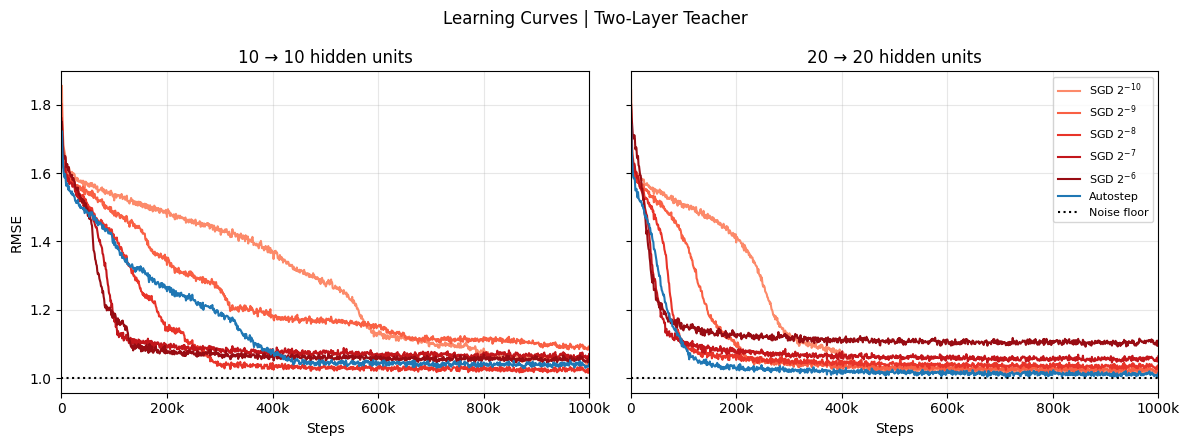

In [14]:
LABELS = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS] + ['Autostep']
COLORS = [*plt.cm.Reds(np.linspace(.4, .9, len(SGD_EXPONENTS))), 'tab:blue']
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW
ticks = np.arange(0, STEPS + 1, 200_000)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, width in zip(axes, WIDTHS):
    for curve, label, color in zip(mse[width], LABELS, COLORS):
        ax.plot(x, np.sqrt(curve).mean(0), color=color, label=label)
    ax.axhline(1, color='black', ls=':', label='Noise floor')
    ax.set_xticks(ticks, ['0' if t == 0 else f'{t // 1000}k' for t in ticks])
    ax.set(title=f'{width} → {width} hidden units', xlabel='Steps', xlim=(0, STEPS))
    ax.grid(True, alpha=.3)
axes[0].set_ylabel('RMSE')
axes[1].legend(fontsize=8)
fig.suptitle('Learning Curves | Two-Layer Teacher')
fig.tight_layout()
plt.show()